# 1_baselines - MaxVer e Random Forest treinados no TerraClass Pará (2008 e 2010)

Treina e avalia os classificadores de referência (MaxVer e Random Forest) com o conjunto gerado em `0b_conjunto_treino`: patches do TerraClass 2008 e 2010 de todo o Pará, excluída a órbita/ponto da área de estudo. As divisões são as do 0b, **agrupadas por órbita-ponto**: teste = fold *f*, validação = fold *f* + 1, treino = os outros três folds. Cada órbita-ponto, com as duas datas, fica inteira num só desses conjuntos.

Cada classificador tem **um único modelo** para as duas datas e todas as cenas. É esse modelo que o `3_inferencia` aplica às seis imagens da área de estudo (2005–2010).

- **MaxVer** gaussiano multivariado, no pixel central.
- **RF** (200 árvores, `class_weight="balanced"`), no pixel central.
- **RF com contexto**: pixel central + média e desvio-padrão de cada banda numa janela em volta dele. O objetivo aqui é separar o ganho de "suavização espacial" do ganho de textura aprendida pela CNN. Há uma variante por janela (5 × 5, 7 × 7 e 9 × 9), para comparar com a CNN do mesmo tamanho de patch.

| | Projeto atual | Aqui |
|---|---|---|
| Amostras | seis datas da área de estudo | TerraClass 2008 e 2010 do Pará, fora da área de estudo |
| Grupo dos folds | região amostral | órbita-ponto (coluna `local`) |
| MaxVer | `por_data` e `conjunto` | um só modelo: não há amostras das datas de aplicação |
| Classes | 6, sem AG em 2006 e 2009 | 4 (F, VS, PA, AG), possíveis em todas as datas |
| Padronização | por cena | escala fixa do 0b (`escala_fixa.json`) |
| RF com contexto | janela 5 × 5 | 5 × 5, 7 × 7 e 9 × 9 |

**Probabilidades com classes equiprováveis.** O MaxVer usa *probabilidades a priori* iguais e o RF usa pesos balanceados, como a perda ponderada da CNN. Assim, as saídas são proporcionais às verossimilhanças, que é o que o CMAP recebe. Por coerência, o NLL, o Brier, o ECE e a calibração usam **pesos balanceados por classe** no conjunto avaliado.

**Calibração.** Todos os classificadores passam pelo mesmo *temperature scaling* (aplicado às log-probabilidades), ajustado na validação. São reportadas as versões bruta e calibrada; a temperatura não muda a classe mais provável, só a confiança.

**Como ler os resultados.** A amostragem do 0a é estratificada (até 300 pixels por classe, cena e ano), então a acurácia global reflete a proporção das amostras, não a do mapa do TerraClass. As métricas principais aqui são a **acurácia balanceada** e as métricas de probabilidade. Estes números medem a generalização **entre órbitas-ponto do Pará**. A avaliação dos resultados é feita na área de estudo (`4_cmap`), que não está em nenhum fold (hehehehehe). Por isso, a escolha da janela (e, depois, do tamanho do patch da CNN) pode usar estes resultados sem contaminar a avaliação final.

Lê só `resultados\0b_conjunto_treino\<NOME_CONJUNTO>\`; grava só em `resultados\1_baselines\<NOME_EXPERIMENTO>\`.

## Parâmetros

In [ ]:
# ============================== PARÂMETROS ==============================
PASTA_PROJETO    = r"C:\cmap_ftl\terraclass"
NOME_CONJUNTO    = "6bandas"                         # subpasta do 0b_conjunto_treino
PASTA_CONJUNTO   = rf"{PASTA_PROJETO}\resultados\0b_conjunto_treino\{NOME_CONJUNTO}"
NOME_EXPERIMENTO = "6bandas_experimento_inicial"                         # um nome por variação (bandas, janelas, árvores...)
PASTA_SAIDA      = rf"{PASTA_PROJETO}\resultados\1_baselines\{NOME_EXPERIMENTO}"

BANDAS_USADAS = ["B1", "B2", "B3", "B4", "B5", "B7"]   # subconjunto das bandas do 0b; ["B2", "B4", "B5"] = Reis et al.
REPETICOES = [0, 1, 2, 3, 4]
FOLDS = [0, 1, 2, 3, 4]

RIDGE = 1e-6                  # regularização da diagonal da covariância do MaxVer (pra não dar merda com inversão de matriz)
RF_N_ARVORES = 200            # número razoável para o tamanho do conjunto de treino (cerca de 10k amostras)
RF_SEMENTE = 42
EPS_RF = 1e-4                 # piso das probabilidades do RF (evita dar merda com log de zero)
JANELAS_CONTEXTO = [5, 7, 9]  # janelas do RF com contexto (ímpares, até 9); [] desliga

CALIBRAR = True               # se True, calibra as probabilidades do RF com Platt Scaling (sigmoid) ou Isotonic Regression; se False, não calibra
N_FAIXAS_ECE = 15             # número de faixas para o cálculo do ECE (Expected Calibration Error)

## 1. Conjunto de treino e atributos

Lê os patches e os metadados do `0b_conjunto_treino` e monta os atributos de cada classificador a partir dos patches (já em unidades z da escala fixa): o pixel central para MaxVer e RF e, para cada janela, o pixel central + média + desvio de cada banda na janela (RF com contexto).

Os parâmetros ficam gravados em `config_baselines.json`. Se a pasta de saída já tiver resultados feitos com outros parâmetros, o notebook para, para não misturar experimentos. Para novos experimentos usar outro `NOME_EXPERIMENTO`. Com os mesmos parâmetros, é possível rodar as divisões em partes (por exemplo, `REPETICOES = [0]` e depois `[1, 2, 3, 4]`); as divisões refeitas substituem as antigas na tabela.

In [2]:
import os, json, time
import numpy as np
import pandas as pd
from sklearn.ensemble import RandomForestClassifier
import matplotlib.pyplot as plt

if not os.path.abspath(PASTA_SAIDA).lower().startswith(os.path.abspath(PASTA_PROJETO).lower() + os.sep):
    raise ValueError(f"PASTA_SAIDA precisa ficar dentro de {PASTA_PROJETO}")
os.makedirs(PASTA_SAIDA, exist_ok=True)

config = {"conjunto": NOME_CONJUNTO, "bandas": BANDAS_USADAS, "janelas_contexto": JANELAS_CONTEXTO, "ridge": RIDGE,
          "rf_n_arvores": RF_N_ARVORES, "rf_semente": RF_SEMENTE, "eps_rf": EPS_RF, "calibrar": CALIBRAR,
          "n_faixas_ece": N_FAIXAS_ECE}
arq_config = os.path.join(PASTA_SAIDA, "config_baselines.json")
if os.path.exists(arq_config):
    with open(arq_config, encoding="utf-8") as arq:
        config_anterior = json.load(arq)
    if config_anterior != config:
        raise ValueError(f"{PASTA_SAIDA} já tem resultados feitos com outros parâmetros:\n{config_anterior}\n"
                         "Use outro NOME_EXPERIMENTO (ou apague a pasta).")
with open(arq_config, "w", encoding="utf-8") as arq:
    json.dump(config, arq, indent=2, ensure_ascii=False)

# ---- legenda e bandas do conjunto
with open(os.path.join(PASTA_CONJUNTO, "legenda.json"), encoding="utf-8") as arq:
    legenda = json.load(arq)
CLASSES = {int(k): v for k, v in legenda["classes"].items()}
CODIGOS = sorted(CLASSES)
SIGLAS = [CLASSES[c] for c in CODIGOS]
K = len(CODIGOS)
faltam = [b for b in BANDAS_USADAS if b not in legenda["bandas"]]
if faltam:
    raise ValueError(f"Bandas {faltam} não estão no conjunto {NOME_CONJUNTO} ({legenda['bandas']})")
ib = [legenda["bandas"].index(b) for b in BANDAS_USADAS]

# ---- patches e metadados
X = np.load(os.path.join(PASTA_CONJUNTO, "patches_9x9.npy"), mmap_mode="r")      # (n, bandas, 9, 9), unidades z
meta = pd.read_csv(os.path.join(PASTA_CONJUNTO, "metadados_patches.csv"))
if len(meta) != len(X):
    raise ValueError(f"metadados ({len(meta)}) e patches ({len(X)}) com tamanhos diferentes")
if not set(meta["classe"]) <= set(CODIGOS):
    raise ValueError(f"Classes nos metadados fora da legenda: {sorted(set(meta['classe']) - set(CODIGOS))}")
y_todos = np.searchsorted(CODIGOS, meta["classe"].to_numpy())
borda_todos = meta["dist_borda_px"].to_numpy() == 1
N_FOLDS = int(meta["fold_r0"].max()) + 1
n_reps = len([c for c in meta.columns if c.startswith("fold_r")])
if max(REPETICOES) >= n_reps or max(FOLDS) >= N_FOLDS:
    raise ValueError(f"O conjunto tem {n_reps} repetições e {N_FOLDS} folds")

# ---- atributos
c = X.shape[-1] // 2
centro = np.asarray(X[:, ib, c, c], dtype=np.float64)                 # (n, bandas): pixel central
atributos = {"RF": centro}
for janela in JANELAS_CONTEXTO:
    if janela % 2 == 0 or janela > X.shape[-1]:
        raise ValueError(f"Janela {janela} inválida: precisa ser ímpar e no máximo {X.shape[-1]}")
    m = janela // 2
    J = np.asarray(X[:, ib, c - m:c + m + 1, c - m:c + m + 1], dtype=np.float64)
    atributos[f"RF_contexto_{janela}x{janela}"] = np.concatenate([centro, J.mean(axis=(2, 3)), J.std(axis=(2, 3))], axis=1)
    del J
NOMES = ["MaxVer"] + list(atributos)

print(f"{len(meta)} patches | {meta['local'].nunique()} órbitas-ponto | anos {sorted(meta['ano'].unique())} | "
      f"{N_FOLDS} folds x {n_reps} repetições")
print(f"Bandas: {BANDAS_USADAS} | classificadores: {NOMES}")
print(f"Atributos: {centro.shape[1]} (pixel)" + "".join(f", {a.shape[1]} ({n})" for n, a in atributos.items() if n != "RF"))
print("\nPatches por ano e classe:")
print(pd.crosstab(meta["ano"], meta["classe_sigla"]).reindex(columns=SIGLAS, fill_value=0).to_string())

100643 patches | 63 órbitas-ponto | anos [np.int64(2008), np.int64(2010)] | 5 folds x 5 repetições
Bandas: ['B1', 'B2', 'B3', 'B4', 'B5', 'B7'] | classificadores: ['MaxVer', 'RF', 'RF_contexto_5x5', 'RF_contexto_7x7', 'RF_contexto_9x9']
Atributos: 6 (pixel), 18 (RF_contexto_5x5), 18 (RF_contexto_7x7), 18 (RF_contexto_9x9)

Patches por ano e classe:
classe_sigla      F     VS     PA    AG
ano                                    
2008          18828  17489  16132  2459
2010          14945  14068  14050  2672


## 2. Treino e avaliação por divisão

Para cada repetição *r* e fold de teste *f*: ajusta os modelos no treino, estima a temperatura na validação e calcula as métricas no teste. As log-probabilidades do teste ficam em `probs_baselines_rR_fF.npz` (chave `logp_<classificador>_<bruto|calibrado>`, na ordem de `id_teste`).

A semente do RF de cada divisão é `RF_SEMENTE + 100·r + f`, a mesma em todas as variantes. O `3_inferencia` refaz os modelos com essas sementes e confere as probabilidades do teste com as gravadas aqui.

In [3]:
resultados = []
inicio = time.time()
divisoes = [(r, f) for r in REPETICOES for f in FOLDS]
for n_feitas, (r, f) in enumerate(divisoes, 1):
    t_div = time.time()
    fv = (f + 1) % N_FOLDS
    fold = meta[f"fold_r{r}"].to_numpy()
    m_te, m_va = fold == f, fold == fv
    m_tr = ~(m_te | m_va)
    sem_treino = [SIGLAS[k] for k in range(K) if not (m_tr & (y_todos == k)).any()]
    if sem_treino:
        raise ValueError(f"r={r} f={f}: classes sem amostra de treino: {sem_treino}")
    idx_av = np.nonzero(m_te | m_va)[0]          # validação + teste
    y_tr = y_todos[m_tr]
    logp_av = {}

    # ---------------- MaxVer gaussiano multivariado (um modelo para todas as cenas e datas)
    ll = np.empty((len(idx_av), K))
    Xe = centro[idx_av]
    for k in range(K):
        Xk = centro[m_tr & (y_todos == k)]
        mu, cov = Xk.mean(axis=0), np.cov(Xk, rowvar=False) + RIDGE * np.eye(Xk.shape[1])
        d = Xe - mu
        _, logdet = np.linalg.slogdet(cov)
        maha = np.einsum("ij,jk,ik->i", d, np.linalg.inv(cov), d)
        ll[:, k] = -0.5 * (maha + logdet + d.shape[1] * np.log(2 * np.pi))
    mx = ll.max(axis=1, keepdims=True)
    logp_av["MaxVer"] = ll - (mx + np.log(np.exp(ll - mx).sum(axis=1, keepdims=True)))

    # ---------------- Random Forest (pixel) e Random Forest com contexto
    for nome_rf, atrib in atributos.items():
        rf = RandomForestClassifier(n_estimators=RF_N_ARVORES, class_weight="balanced", n_jobs=-1,
                                    random_state=RF_SEMENTE + 100 * r + f)
        rf.fit(atrib[m_tr], y_tr)
        Pr = np.zeros((len(idx_av), K))
        Pr[:, rf.classes_] = rf.predict_proba(atrib[idx_av])
        Pr = np.clip(Pr, EPS_RF, None)
        Pr = Pr / Pr.sum(axis=1, keepdims=True)
        logp_av[nome_rf] = np.log(Pr)
        del rf

    # ---------------- calibração na validação e métricas no teste
    sel_va, sel_te = m_va[idx_av], m_te[idx_av]
    y_val, y = y_todos[idx_av][sel_va], y_todos[idx_av][sel_te]
    cont = np.bincount(y_val, minlength=K)
    pesos_val = len(y_val) / (np.count_nonzero(cont) * cont[y_val])
    cont = np.bincount(y, minlength=K)
    pesos = len(y) / (np.count_nonzero(cont) * cont[y])
    borda = borda_todos[idx_av][sel_te]
    salvar = {"id_teste": meta["id"].to_numpy()[idx_av][sel_te]}
    for nome, lp in logp_av.items():
        logp_val = lp[sel_va]
        # ---- temperature scaling: busca em grade do T que minimiza o NLL balanceado na validação
        melhor_T, melhor_nll = 1.0, np.inf
        idx_val = np.arange(len(y_val))
        for T in np.exp(np.linspace(np.log(0.05), np.log(20.0), 300)):
            z = logp_val / T
            z = z - z.max(axis=1, keepdims=True)
            lse = np.log(np.exp(z).sum(axis=1))
            nll_T = -(pesos_val * (z[idx_val, y_val] - lse)).sum() / pesos_val.sum()
            if nll_T < melhor_nll:
                melhor_T, melhor_nll = float(T), float(nll_T)
        for versao in (["bruto", "calibrado"] if CALIBRAR else ["bruto"]):
            if versao == "bruto":
                logp = lp[sel_te]
            else:
                z = lp[sel_te] / melhor_T
                z = z - z.max(axis=1, keepdims=True)
                logp = z - np.log(np.exp(z).sum(axis=1, keepdims=True))
            linha = {"repeticao": r, "fold_teste": f, "classificador": nome, "versao": versao,
                     "T": melhor_T if versao == "calibrado" else 1.0, "n_treino": int(m_tr.sum()),
                     "n_validacao": len(y_val), "n_teste": len(y)}
            # ---- métricas no conjunto de teste
            P = np.exp(logp)
            pred = P.argmax(axis=1)
            cm = np.zeros((K, K), dtype=np.int64)
            np.add.at(cm, (y, pred), 1)
            n_tot = cm.sum()
            oa = np.trace(cm) / n_tot
            pe = (cm.sum(axis=0) * cm.sum(axis=1)).sum() / n_tot ** 2
            kappa = (oa - pe) / (1 - pe)
            n_ref, n_pred = cm.sum(axis=1), cm.sum(axis=0)
            acur_produtor = np.where(n_ref > 0, np.diag(cm) / np.maximum(n_ref, 1), np.nan)
            acur_usuario = np.where(n_pred > 0, np.diag(cm) / np.maximum(n_pred, 1), np.nan)
            idx = np.arange(len(y))
            p_verdadeira = np.clip(P[idx, y], 1e-12, 1.0)
            nll = -(pesos * np.log(p_verdadeira)).sum() / pesos.sum()
            brier = (pesos * ((P - np.eye(K)[y]) ** 2).sum(axis=1)).sum() / pesos.sum()
            confianca, acerto = P.max(axis=1), pred == y
            limites = np.linspace(0, 1, N_FAIXAS_ECE + 1)
            ece = 0.0
            for b in range(N_FAIXAS_ECE):
                sel = (confianca > limites[b]) & (confianca <= limites[b + 1])
                if sel.any():
                    w = pesos[sel]
                    ece += abs((w * acerto[sel]).sum() / w.sum() - (w * confianca[sel]).sum() / w.sum()) * w.sum() / pesos.sum()
            linha.update({"acuracia_global": oa, "kappa": kappa, "acuracia_balanceada": np.nanmean(acur_produtor[n_ref > 0]),
                          "nll_balanceado": nll, "brier_balanceado": brier, "ece": ece,
                          "acuracia_borda": acerto[borda].mean(), "acuracia_interior": acerto[~borda].mean()})
            for k in range(K):
                linha[f"AP_{SIGLAS[k]}"] = acur_produtor[k]
                linha[f"AU_{SIGLAS[k]}"] = acur_usuario[k]
            resultados.append(linha)
            salvar[f"logp_{nome}_{versao}"] = logp.astype(np.float32)
    np.savez_compressed(os.path.join(PASTA_SAIDA, f"probs_baselines_r{r}_f{f}.npz"), **salvar)
    da_divisao = [l for l in resultados[-len(logp_av) * (2 if CALIBRAR else 1):] if l["versao"] == "bruto"]
    decorrido = time.time() - inicio
    print(f"r={r} f={f} ({time.time() - t_div:.0f} s; faltam ~{decorrido / n_feitas * (len(divisoes) - n_feitas) / 60:.0f} min) "
          f"| acurácia balanceada no teste: " + ", ".join(f"{l['classificador']}={l['acuracia_balanceada']:.3f}" for l in da_divisao))

# ---- junta com divisões de execuções anteriores (mesmos parâmetros); as refeitas agora substituem as antigas
tab_resultados = pd.DataFrame(resultados)
arq_resultados = os.path.join(PASTA_SAIDA, "resultados_baselines.csv")
if os.path.exists(arq_resultados):
    anterior = pd.read_csv(arq_resultados)
    refeitas = set(zip(tab_resultados["repeticao"], tab_resultados["fold_teste"]))
    manter = [(a, b) not in refeitas for a, b in zip(anterior["repeticao"], anterior["fold_teste"])]
    tab_resultados = pd.concat([anterior[manter], tab_resultados], ignore_index=True)
tab_resultados = tab_resultados.sort_values(["repeticao", "fold_teste", "classificador", "versao"]).reset_index(drop=True)
tab_resultados.to_csv(arq_resultados, index=False)
n_div = tab_resultados[["repeticao", "fold_teste"]].drop_duplicates().shape[0]
print(f"\nConcluído em {(time.time() - inicio) / 60:.1f} min | {n_div} divisões em resultados_baselines.csv")

r=0 f=0 (19 s; faltam ~7 min) | acurácia balanceada no teste: MaxVer=0.554, RF=0.583, RF_contexto_5x5=0.637, RF_contexto_7x7=0.647, RF_contexto_9x9=0.653
r=0 f=1 (23 s; faltam ~8 min) | acurácia balanceada no teste: MaxVer=0.583, RF=0.625, RF_contexto_5x5=0.693, RF_contexto_7x7=0.702, RF_contexto_9x9=0.708
r=0 f=2 (24 s; faltam ~8 min) | acurácia balanceada no teste: MaxVer=0.594, RF=0.649, RF_contexto_5x5=0.694, RF_contexto_7x7=0.701, RF_contexto_9x9=0.709
r=0 f=3 (21 s; faltam ~8 min) | acurácia balanceada no teste: MaxVer=0.565, RF=0.589, RF_contexto_5x5=0.642, RF_contexto_7x7=0.652, RF_contexto_9x9=0.654
r=0 f=4 (23 s; faltam ~7 min) | acurácia balanceada no teste: MaxVer=0.586, RF=0.586, RF_contexto_5x5=0.658, RF_contexto_7x7=0.673, RF_contexto_9x9=0.674
r=1 f=0 (24 s; faltam ~7 min) | acurácia balanceada no teste: MaxVer=0.617, RF=0.670, RF_contexto_5x5=0.724, RF_contexto_7x7=0.729, RF_contexto_9x9=0.735
r=1 f=1 (22 s; faltam ~7 min) | acurácia balanceada no teste: MaxVer=0.579, 

## 3. Resumo

Média e desvio-padrão entre as divisões (teste). A acurácia balanceada e as métricas de probabilidade usam pesos iguais por classe. A acurácia de borda (pixel central com outro rótulo na janela 3 × 3, `dist_borda_px` = 1) e a de interior (`dist_borda_px` ≥ 2) são acurácias simples, sem pesos: as duas misturam as classes em proporções diferentes.

In [4]:
metricas = ["acuracia_balanceada", "acuracia_global", "kappa", "nll_balanceado", "brier_balanceado", "ece",
            "acuracia_interior", "acuracia_borda"]
ordem = {nome: i for i, nome in enumerate(NOMES)}
resumo = tab_resultados.groupby(["classificador", "versao"])[metricas].agg(["mean", "std"])
resumo.columns = [f"{a}_{b}" for a, b in resumo.columns]
resumo["n_divisoes"] = tab_resultados.groupby(["classificador", "versao"]).size()
resumo = resumo.sort_index(key=lambda s: s.map(ordem) if s.name == "classificador" else s)
resumo.to_csv(os.path.join(PASTA_SAIDA, "resumo_baselines.csv"))
tabela = pd.DataFrame(index=resumo.index)
for mt in metricas:
    tabela[mt] = [f"{a:.3f} ± {b:.3f}" for a, b in zip(resumo[f"{mt}_mean"], resumo[f"{mt}_std"])]
tabela["n_divisoes"] = resumo["n_divisoes"]
display(tabela)

print("Temperatura ajustada na validação (média e faixa entre divisões):")
temp = tab_resultados[tab_resultados["versao"] == "calibrado"].groupby("classificador")["T"].agg(["mean", "min", "max"])
print(temp.reindex(NOMES).round(3).to_string())

acuracia_balanceada acuracia_global          kappa  \
classificador   versao                                                         
MaxVer          bruto           0.569 ± 0.045   0.569 ± 0.020  0.382 ± 0.033   
                calibrado       0.569 ± 0.045   0.569 ± 0.020  0.382 ± 0.033   
RF              bruto           0.602 ± 0.049   0.625 ± 0.019  0.458 ± 0.031   
                calibrado       0.602 ± 0.049   0.625 ± 0.019  0.458 ± 0.031   
RF_contexto_5x5 bruto           0.659 ± 0.051   0.685 ± 0.021  0.545 ± 0.033   
                calibrado       0.659 ± 0.051   0.685 ± 0.021  0.545 ± 0.033   
RF_contexto_7x7 bruto           0.669 ± 0.052   0.694 ± 0.021  0.559 ± 0.033   
                calibrado       0.669 ± 0.052   0.694 ± 0.021  0.559 ± 0.033   
RF_contexto_9x9 bruto           0.674 ± 0.052   0.700 ± 0.021  0.566 ± 0.032   
                calibrado       0.674 ± 0.052   0.700 ± 0.021  0.566 ± 0.032   

                          nll_balanceado brier_balanceado            ece  \
classificador   versao                                                     
MaxVer          bruto      1.223 ± 0.214    0.578 ± 0.063  0.149 ± 0.033   
                calibrado  1.021 ± 0.100    0.553 ± 0.044  0.075 ± 0.030   
RF              bruto      1.035 ± 0.241    0.532 ± 0.067  0.062 ± 0.035   
                calibrado  1.012 ± 0.191    0.539 ± 0.056  0.072 ± 0.063   
RF_contexto_5x5 bruto      0.878 ± 0.228    0.462 ± 0.069  0.039 ± 0.030   
                calibrado  0.889 ± 0.211    0.473 ± 0.062  0.073 ± 0.062   
RF_contexto_7x7 bruto      0.864 ± 0.241    0.451 ± 0.070  0.038 ± 0.029   
                calibrado  0.876 ± 0.222    0.463 ± 0.063  0.074 ± 0.065   
RF_contexto_9x9 bruto      0.855 ± 0.245    0.444 ± 0.071  0.038 ± 0.030   
                calibrado  0.869 ± 0.227    0.456 ± 0.063  0.075 ± 0.064   

                          acuracia_interior acuracia_borda  n_divisoes  
classificador   versao                                                  
MaxVer          bruto         0.648 ± 0.020  0.329 ± 0.026          25  
                calibrado     0.648 ± 0.020  0.329 ± 0.026          25  
RF              bruto         0.698 ± 0.019  0.405 ± 0.017          25  
                calibrado     0.698 ± 0.019  0.405 ± 0.017          25  
RF_contexto_5x5 bruto         0.756 ± 0.019  0.470 ± 0.027          25  
                calibrado     0.756 ± 0.019  0.470 ± 0.027          25  
RF_contexto_7x7 bruto         0.765 ± 0.019  0.483 ± 0.027          25  
                calibrado     0.765 ± 0.019  0.483 ± 0.027          25  
RF_contexto_9x9 bruto         0.769 ± 0.018  0.491 ± 0.029          25  
                calibrado     0.769 ± 0.018  0.491 ± 0.029          25

Temperatura ajustada na validação (média e faixa entre divisões):
                  mean    min    max
classificador                       
MaxVer           2.992  2.207  6.010
RF               1.712  1.117  5.120
RF_contexto_5x5  1.398  0.896  3.715
RF_contexto_7x7  1.406  0.896  3.867
RF_contexto_9x9  1.401  0.860  3.791


In [5]:
# acurácias do produtor (AP) e do usuário (AU) por classe, média entre divisões
cols_ap = [f"AP_{s}" for s in SIGLAS]
cols_au = [f"AU_{s}" for s in SIGLAS]
cal = tab_resultados[tab_resultados["versao"] == "bruto"]
print("Acurácia do produtor (recall):")
print(cal.groupby("classificador")[cols_ap].mean().reindex(NOMES).round(3).set_axis(SIGLAS, axis=1).to_string())
print("\nAcurácia do usuário (precisão):")
print(cal.groupby("classificador")[cols_au].mean().reindex(NOMES).round(3).set_axis(SIGLAS, axis=1).to_string())

Acurácia do produtor (recall):
                     F     VS     PA     AG
classificador                              
MaxVer           0.880  0.341  0.451  0.606
RF               0.762  0.431  0.692  0.522
RF_contexto_5x5  0.809  0.551  0.704  0.572
RF_contexto_7x7  0.813  0.575  0.705  0.581
RF_contexto_9x9  0.814  0.588  0.706  0.588

Acurácia do usuário (precisão):
                     F     VS     PA     AG
classificador                              
MaxVer           0.594  0.466  0.703  0.382
RF               0.667  0.502  0.672  0.709
RF_contexto_5x5  0.772  0.566  0.699  0.752
RF_contexto_7x7  0.793  0.576  0.699  0.765
RF_contexto_9x9  0.803  0.583  0.700  0.772


## 4. Previsão fora do fold (repetição 0)

Nos 5 folds de uma repetição, cada patch cai no teste exatamente uma vez, previsto por um modelo que não viu a órbita-ponto dele. Juntando os testes da repetição 0, obtém-se uma previsão de cada patch, usada para:

- a matriz de confusão de cada classificador;
- a acurácia balanceada por ano (2008 × 2010);
- a acurácia por distância à borda (`dist_borda_px` de 1 a 5; 5 = nenhum outro rótulo na janela 9 × 9). É o dado que ajuda a escolher a janela: uma janela maior tende a ajudar no interior e a atrapalhar perto da borda.

A classe prevista é a de maior probabilidade, igual nas versões bruta e calibrada.

In [6]:
arqs_r0 = [os.path.join(PASTA_SAIDA, f"probs_baselines_r0_f{f}.npz") for f in range(N_FOLDS)]
if not all(os.path.exists(a) for a in arqs_r0):
    print("A repetição 0 não está completa: a previsão fora do fold não foi calculada.")
    pred_oof = None
else:
    posicao = pd.Index(meta["id"])
    pred_oof = {nome: np.full(len(meta), -1) for nome in NOMES}
    for a in arqs_r0:
        with np.load(a) as z:
            ii = posicao.get_indexer(z["id_teste"])
            for nome in NOMES:
                pred_oof[nome][ii] = z[f"logp_{nome}_bruto"].argmax(axis=1)
    if any((p < 0).any() for p in pred_oof.values()):
        raise ValueError("Há patches sem previsão nos testes da repetição 0")

    anos_m = meta["ano"].to_numpy()
    dist_m = meta["dist_borda_px"].to_numpy()
    linhas_cm, linhas_ano, linhas_dist = [], [], []
    for nome in NOMES:
        p = pred_oof[nome]
        for kr in range(K):
            for kp in range(K):
                linhas_cm.append({"classificador": nome, "referencia": SIGLAS[kr], "previsto": SIGLAS[kp],
                                  "n": int(((y_todos == kr) & (p == kp)).sum())})
        for ano in sorted(np.unique(anos_m)):
            s = anos_m == ano
            recall = [(p[s & (y_todos == k)] == k).mean() for k in range(K) if (s & (y_todos == k)).any()]
            linhas_ano.append({"classificador": nome, "ano": int(ano), "acuracia_balanceada": np.mean(recall),
                               "acuracia_global": (p[s] == y_todos[s]).mean(), "n": int(s.sum())})
        for d in sorted(np.unique(dist_m)):
            s = dist_m == d
            linhas_dist.append({"classificador": nome, "dist_borda_px": int(d), "acuracia": (p[s] == y_todos[s]).mean(),
                                "n": int(s.sum())})
    tab_cm = pd.DataFrame(linhas_cm)
    tab_ano = pd.DataFrame(linhas_ano)
    tab_dist = pd.DataFrame(linhas_dist)
    tab_cm.to_csv(os.path.join(PASTA_SAIDA, "fora_do_fold_r0_confusao.csv"), index=False)
    tab_ano.to_csv(os.path.join(PASTA_SAIDA, "fora_do_fold_r0_por_ano.csv"), index=False)
    tab_dist.to_csv(os.path.join(PASTA_SAIDA, "fora_do_fold_r0_por_dist_borda.csv"), index=False)

    for nome in NOMES:
        cm = tab_cm[tab_cm["classificador"] == nome].pivot(index="referencia", columns="previsto", values="n")
        print(f"\n{nome} — matriz de confusão (linhas = referência TerraClass, colunas = previsto):")
        print(cm.reindex(index=SIGLAS, columns=SIGLAS).to_string())
    print("\nAcurácia balanceada por ano:")
    print(tab_ano.pivot(index="classificador", columns="ano", values="acuracia_balanceada").reindex(NOMES).round(3).to_string())
    print("\nAcurácia por distância à borda:")
    print(tab_dist.pivot(index="classificador", columns="dist_borda_px", values="acuracia").reindex(NOMES).round(3).to_string())
    print("patches: " + ", ".join(f"{d} px = {n}" for d, n in tab_dist.groupby("dist_borda_px")["n"].first().items()))


MaxVer — matriz de confusão (linhas = referência TerraClass, colunas = previsto):
previsto        F     VS     PA    AG
referencia                           
F           29685   3159    668   261
VS          16148  10859   3762   788
PA           3974   8779  13593  3836
AG            242    523   1219  3147

RF — matriz de confusão (linhas = referência TerraClass, colunas = previsto):
previsto        F     VS     PA    AG
referencia                           
F           25724   6985   1040    24
VS          10624  13586   7233   114
PA           2220   6254  20874   834
AG            133    393   1969  2636

RF_contexto_5x5 — matriz de confusão (linhas = referência TerraClass, colunas = previsto):
previsto        F     VS     PA    AG
referencia                           
F           27390   5590    781    12
VS           7287  17410   6742   118
PA            915   7310  21281   676
AG             26    492   1707  2906

RF_contexto_7x7 — matriz de confusão (linhas = referência Ter

## 5. Figura

À esquerda, acurácias no teste (média ± desvio entre divisões). À direita, acurácia por distância à borda na previsão fora do fold da repetição 0.

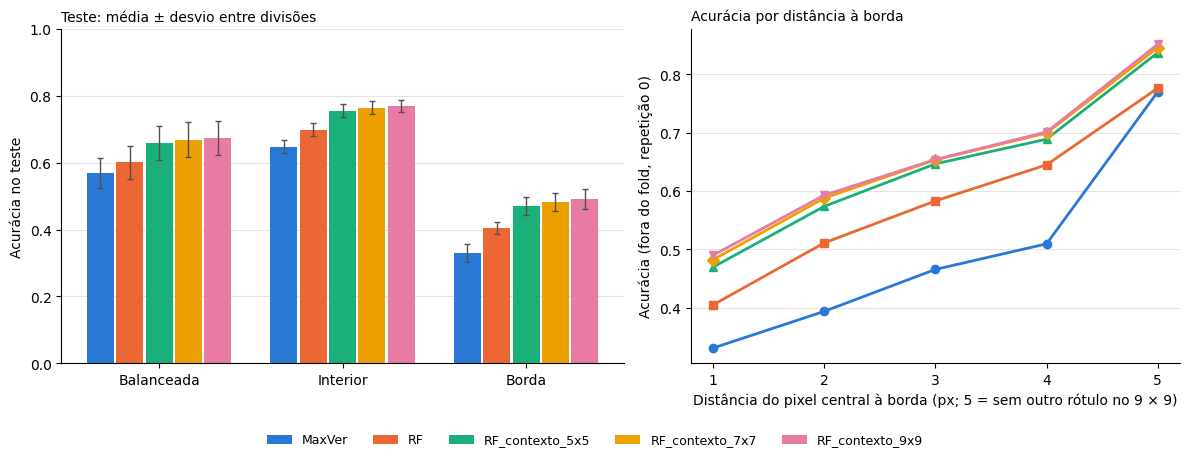

In [7]:
CORES = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
MARCADORES = ["o", "s", "^", "D", "v", "P", "X", "*"]
bruto = resumo.xs("bruto", level="versao").reindex(NOMES)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.6), gridspec_kw={"width_ratios": [1.15, 1]})

grupos = [("acuracia_balanceada", "Balanceada"), ("acuracia_interior", "Interior"), ("acuracia_borda", "Borda")]
largura = 0.8 / len(NOMES)
for i, nome in enumerate(NOMES):
    x = np.arange(len(grupos)) - 0.4 + largura * (i + 0.5)
    ax1.bar(x, [bruto.loc[nome, f"{g}_mean"] for g, _ in grupos], width=largura * 0.92, color=CORES[i], label=nome,
            yerr=[bruto.loc[nome, f"{g}_std"] for g, _ in grupos], error_kw={"elinewidth": 1, "capsize": 2, "ecolor": "#52514e"})
ax1.set_xticks(np.arange(len(grupos)), [g for _, g in grupos])
ax1.set_ylabel("Acurácia no teste")
ax1.set_ylim(0, 1)
ax1.set_title("Teste: média ± desvio entre divisões", fontsize=10, loc="left")

if pred_oof is not None:
    for i, nome in enumerate(NOMES):
        t = tab_dist[tab_dist["classificador"] == nome]
        ax2.plot(t["dist_borda_px"], t["acuracia"], color=CORES[i], marker=MARCADORES[i], markersize=6, linewidth=2, label=nome)
    ax2.set_xticks(sorted(tab_dist["dist_borda_px"].unique()))
    ax2.set_xlabel("Distância do pixel central à borda (px; 5 = sem outro rótulo no 9 × 9)")
    ax2.set_ylabel("Acurácia (fora do fold, repetição 0)")
    ax2.set_title("Acurácia por distância à borda", fontsize=10, loc="left")
for ax in (ax1, ax2):
    ax.grid(axis="y", color="#e4e3de", linewidth=0.8)
    ax.set_axisbelow(True)
    for lado in ("top", "right"):
        ax.spines[lado].set_visible(False)
alcas, rotulos = ax1.get_legend_handles_labels()
fig.legend(alcas, rotulos, loc="lower center", ncol=len(NOMES), frameon=False, fontsize=9)
fig.tight_layout(rect=(0, 0.07, 1, 1))
fig.savefig(os.path.join(PASTA_SAIDA, "resumo_baselines.png"), dpi=150, bbox_inches="tight")
plt.show()

## 6. Saídas

| Arquivo | Conteúdo |
|---|---|
| `config_baselines.json` | parâmetros usados (protege a pasta contra mistura de experimentos) |
| `probs_baselines_rR_fF.npz` | log-probabilidades do teste de cada divisão (`id_teste`, `logp_<classificador>_<bruto\|calibrado>`) |
| `resultados_baselines.csv` | uma linha por divisão, classificador e versão: temperatura, acurácias, kappa, NLL, Brier, ECE, borda/interior, AP e AU por classe |
| `resumo_baselines.csv` | média e desvio entre divisões |
| `fora_do_fold_r0_confusao.csv` | matriz de confusão de cada classificador (repetição 0, cada patch uma vez) |
| `fora_do_fold_r0_por_ano.csv` | acurácia balanceada e global por ano |
| `fora_do_fold_r0_por_dist_borda.csv` | acurácia por distância à borda |
| `resumo_baselines.png` | figura da seção 5 |

O `3_inferencia` adaptado vai ler `config_baselines.json` e `resultados_baselines.csv` (temperaturas) desta pasta, refazer os modelos com as mesmas sementes e conferir as probabilidades do teste com os `.npz`.

In [8]:
total = sum(os.path.getsize(os.path.join(PASTA_SAIDA, a)) for a in os.listdir(PASTA_SAIDA))
print(f"Saídas em {PASTA_SAIDA}: {len(os.listdir(PASTA_SAIDA))} arquivos, {total / 1e6:.0f} MB")

Saídas em C:\cmap_ftl\terraclass\resultados\1_baselines\6bandas_experimento_inicial: 32 arquivos, 50 MB
